In [ ]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn import metrics

from keras.datasets import mnist
from keras import models
from keras import layers
from keras.utils import to_categorical

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

# Zadatak 1

In [ ]:
df = pd.read_csv("drive/MyDrive/Colab Notebooks/Vjestacka inteligencija/VI L2/izvjestaj.csv")

In [ ]:
df.head()

,id,Indeks,Prisustvo,Ispit1,Ispit2,Ispit1_popravni,Ispit2_popravni,UKUPNO,Ocjena
0,1,94-ST,10,9.4,7.5,12.08,13.73,35.81,7
1,2,77-ST,10,8.5,/,/,/,35.50,7
2,3,69-ST,10,17,/,/,/,39.50,9
3,4,79-ST,0,7.6,4.8,/,/,12.40,/
4,5,89-ST,10,10.6,12.5,12.58,/,35.08,6


In [ ]:
df.tail(10)

,id,Indeks,Prisustvo,Ispit1,Ispit2,Ispit1_popravni,Ispit2_popravni,UKUPNO,Ocjena
37,38,71-ST,10,/,/,/,/,42.16,8
38,39,54-ST,10,/,/,/,/,19.35,/
39,40,60-ST,10,10,/,/,/,38.50,6
40,41,48-ST,10,/,/,/,/,10.00,6
41,42,61-ST,10,/,/,/,/,23.12,/
42,43,1-ST,10,/,/,/,/,10.00,/
43,44,88-ST,10,/,/,/,/,37.00,7
44,45,75-ST,10,/,/,9.83,13.5,33.33,6
45,46,67-ST,10,16.5,/,/,/,39.50,7
46,47,81-ST,10,15.7,17.3,/,/,43.00,8


In [ ]:
df[["Ispit1", "Ispit2"]]

,Ispit1,Ispit2
0,9.4,7.5
1,8.5,/
2,17,/
3,7.6,4.8
4,10.6,12.5
5,/,/
6,/,12.5
7,/,/
8,/,/
9,/,/


In [ ]:
df.loc[df["Prisustvo"] == 0]

,id,Indeks,Prisustvo,Ispit1,Ispit2,Ispit1_popravni,Ispit2_popravni,UKUPNO,Ocjena
3,4,79-ST,0,7.6,4.8,/,/,12.40,/
5,6,78-ST,0,/,/,13.08,12.83,25.91,6
8,9,83-ST,0,/,/,/,/,0.00,/
22,23,74-ST,0,10.7,/,14.58,11.7,27.08,/
28,29,95-ST,0,10.8,12.5,7.25,/,23.50,/
31,32,41-ST,0,/,/,/,/,5.87,/
32,33,17-ST,0,7.5,1.7,2.33,/,9.20,/
33,34,82-ST,0,10,1.5,/,/,16.00,/
34,35,15-ST,0,/,/,/,/,0.00,/


In [ ]:
df.loc[df["Ocjena"].isin(["8", "9", "10"]), ["Indeks", "UKUPNO", "Ocjena"]]

,Indeks,UKUPNO,Ocjena
2,69-ST,39.50,9
6,93-ST,35.17,8
7,68-ST,50.00,9
9,92-ST,42.06,9
10,65-ST,43.19,8
12,90-ST,39.90,8
13,97-ST,41.05,9
14,84-ST,43.56,9
16,91-ST,43.48,9
19,96-ST,41.40,8


In [ ]:
df.replace('/', np.nan, inplace=True)
df.head()

,id,Indeks,Prisustvo,Ispit1,Ispit2,Ispit1_popravni,Ispit2_popravni,UKUPNO,Ocjena
0,1,94-ST,10,9.4,7.5,12.08,13.73,35.81,7
1,2,77-ST,10,8.5,NaN,NaN,NaN,35.50,7
2,3,69-ST,10,17,NaN,NaN,NaN,39.50,9
3,4,79-ST,0,7.6,4.8,NaN,NaN,12.40,NaN
4,5,89-ST,10,10.6,12.5,12.58,NaN,35.08,6


In [ ]:
for col in df.columns:
    try:
        df[col] = pd.to_numeric(df[col], errors='raise')
    except ValueError:
        pass

df.dtypes

,0
id,int64
Indeks,object
Prisustvo,int64
Ispit1,float64
Ispit2,float64
Ispit1_popravni,float64
Ispit2_popravni,float64
UKUPNO,float64
Ocjena,float64


In [ ]:
df.dropna(subset=["Ocjena"], inplace=True)
df.head()

,id,Indeks,Prisustvo,Ispit1,Ispit2,Ispit1_popravni,Ispit2_popravni,UKUPNO,Ocjena
0,1,94-ST,10,9.4,7.5,12.08,13.73,35.81,7.0
1,2,77-ST,10,8.5,NaN,NaN,NaN,35.50,7.0
2,3,69-ST,10,17.0,NaN,NaN,NaN,39.50,9.0
4,5,89-ST,10,10.6,12.5,12.58,NaN,35.08,6.0
5,6,78-ST,0,NaN,NaN,13.08,12.83,25.91,6.0


In [ ]:
def max_nan(x, y):
    if np.isnan(x) or np.isnan(y):
        return x if not np.isnan(x) else y
    return max(x, y)

In [ ]:
df['Ispit1_final'] = df['Ispit1'].combine(df['Ispit1_popravni'], max_nan)
df['Ispit2_final'] = df['Ispit2'].combine(df['Ispit2_popravni'], max_nan)
df.head()

,id,Indeks,Prisustvo,Ispit1,Ispit2,Ispit1_popravni,Ispit2_popravni,UKUPNO,Ocjena,Ispit1_final,Ispit2_final
0,1,94-ST,10,9.4,7.5,12.08,13.73,35.81,7.0,12.08,13.73
1,2,77-ST,10,8.5,NaN,NaN,NaN,35.50,7.0,8.50,NaN
2,3,69-ST,10,17.0,NaN,NaN,NaN,39.50,9.0,17.00,NaN
4,5,89-ST,10,10.6,12.5,12.58,NaN,35.08,6.0,12.58,12.50
5,6,78-ST,0,NaN,NaN,13.08,12.83,25.91,6.0,13.08,12.83


In [ ]:
df.drop(columns=["Ispit1", "Ispit2", "Ispit1_popravni", "Ispit2_popravni"], inplace=True)
df.head()

,id,Indeks,Prisustvo,UKUPNO,Ocjena,Ispit1_final,Ispit2_final
0,1,94-ST,10,35.81,7.0,12.08,13.73
1,2,77-ST,10,35.50,7.0,8.50,NaN
2,3,69-ST,10,39.50,9.0,17.00,NaN
4,5,89-ST,10,35.08,6.0,12.58,12.50
5,6,78-ST,0,25.91,6.0,13.08,12.83


In [ ]:
df.to_csv("izvjestaj_modificirano.csv", sep=";")

In [ ]:
pickle.dump(
    df,
    open("izvjestaj_modificirano_pickle.p", "wb"),
    protocol=pickle.HIGHEST_PROTOCOL
)

# Zadatak 2

In [ ]:
df = pd.read_csv("drive/MyDrive/Colab Notebooks/Vjestacka inteligencija/VI L2/izvjestaj.csv")
df.replace('/', np.nan, inplace=True)

for col in df.columns:
    try:
        df[col] = pd.to_numeric(df[col], errors='raise')
    except ValueError:
        pass

In [ ]:
df.head(10)

,id,Indeks,Prisustvo,Ispit1,Ispit2,Ispit1_popravni,Ispit2_popravni,UKUPNO,Ocjena
0,1,94-ST,10,9.4,7.5,12.08,13.73,35.81,7.0
1,2,77-ST,10,8.5,NaN,NaN,NaN,35.50,7.0
2,3,69-ST,10,17.0,NaN,NaN,NaN,39.50,9.0
3,4,79-ST,0,7.6,4.8,NaN,NaN,12.40,NaN
4,5,89-ST,10,10.6,12.5,12.58,NaN,35.08,6.0
5,6,78-ST,0,NaN,NaN,13.08,12.83,25.91,6.0
6,7,93-ST,10,NaN,12.5,12.67,NaN,35.17,8.0
7,8,68-ST,10,NaN,NaN,NaN,NaN,50.00,9.0
8,9,83-ST,0,NaN,NaN,NaN,NaN,0.00,NaN
9,10,92-ST,10,NaN,NaN,NaN,NaN,42.06,9.0


In [ ]:
si_median = SimpleImputer(strategy='median')
df[["Ispit1", "Ispit2"]] = si_median.fit_transform(df[["Ispit1", "Ispit2"]])
df.head(10)

,id,Indeks,Prisustvo,Ispit1,Ispit2,Ispit1_popravni,Ispit2_popravni,UKUPNO,Ocjena
0,1,94-ST,10,9.4,7.5,12.08,13.73,35.81,7.0
1,2,77-ST,10,8.5,8.7,NaN,NaN,35.50,7.0
2,3,69-ST,10,17.0,8.7,NaN,NaN,39.50,9.0
3,4,79-ST,0,7.6,4.8,NaN,NaN,12.40,NaN
4,5,89-ST,10,10.6,12.5,12.58,NaN,35.08,6.0
5,6,78-ST,0,12.5,8.7,13.08,12.83,25.91,6.0
6,7,93-ST,10,12.5,12.5,12.67,NaN,35.17,8.0
7,8,68-ST,10,12.5,8.7,NaN,NaN,50.00,9.0
8,9,83-ST,0,12.5,8.7,NaN,NaN,0.00,NaN
9,10,92-ST,10,12.5,8.7,NaN,NaN,42.06,9.0


In [ ]:
si_mean = SimpleImputer(strategy='mean')
df[["Ispit1_popravni", "Ispit2_popravni"]] = si_mean.fit_transform(df[["Ispit1_popravni", "Ispit2_popravni"]])
df.head(10)

,id,Indeks,Prisustvo,Ispit1,Ispit2,Ispit1_popravni,Ispit2_popravni,UKUPNO
0,1,94-ST,10,-1.561766,-0.555596,0.795918,0.401146,35.81
1,2,77-ST,10,-2.029964,-0.087900,0.816327,0.455587,35.50
2,3,69-ST,10,2.391904,-0.087900,0.816327,0.455587,39.50
3,4,79-ST,0,-2.498161,-1.607912,0.816327,0.455587,12.40
4,5,89-ST,10,-0.937502,1.393136,0.836735,0.455587,35.08
5,6,78-ST,0,0.050915,-0.087900,0.877551,0.315186,25.91
6,7,93-ST,10,0.050915,1.393136,0.844082,0.455587,35.17
7,8,68-ST,10,0.050915,-0.087900,0.816327,0.455587,50.00
8,9,83-ST,0,0.050915,-0.087900,0.816327,0.455587,0.00
9,10,92-ST,10,0.050915,-0.087900,0.816327,0.455587,42.06


In [ ]:
ss = StandardScaler()
df[["Ispit1", "Ispit2"]] = ss.fit_transform(df[["Ispit1", "Ispit2"]])
df.head()

,id,Indeks,Prisustvo,Ispit1,Ispit2,Ispit1_popravni,Ispit2_popravni,UKUPNO,Ocjena
0,1,94-ST,10,-1.561766,-0.555596,12.08,13.73,35.81,7.0
1,2,77-ST,10,-2.029964,-0.087900,12.33,14.30,35.50,7.0
2,3,69-ST,10,2.391904,-0.087900,12.33,14.30,39.50,9.0
3,4,79-ST,0,-2.498161,-1.607912,12.33,14.30,12.40,NaN
4,5,89-ST,10,-0.937502,1.393136,12.58,14.30,35.08,6.0


In [ ]:
mms = MinMaxScaler()
df[["Ispit1_popravni", "Ispit2_popravni"]] = mms.fit_transform(df[["Ispit1_popravni", "Ispit2_popravni"]])
df.head()

,id,Indeks,Prisustvo,Ispit1,Ispit2,Ispit1_popravni,Ispit2_popravni,UKUPNO,Ocjena
0,1,94-ST,10,-1.561766,-0.555596,0.795918,0.401146,35.81,7.0
1,2,77-ST,10,-2.029964,-0.087900,0.816327,0.455587,35.50,7.0
2,3,69-ST,10,2.391904,-0.087900,0.816327,0.455587,39.50,9.0
3,4,79-ST,0,-2.498161,-1.607912,0.816327,0.455587,12.40,NaN
4,5,89-ST,10,-0.937502,1.393136,0.836735,0.455587,35.08,6.0


In [ ]:
df.fillna(0, inplace=True)
df.head()

,id,Indeks,Prisustvo,Ispit1,Ispit2,Ispit1_popravni,Ispit2_popravni,UKUPNO,Ocjena
0,1,94-ST,10,-1.561766,-0.555596,0.795918,0.401146,35.81,7.0
1,2,77-ST,10,-2.029964,-0.087900,0.816327,0.455587,35.50,7.0
2,3,69-ST,10,2.391904,-0.087900,0.816327,0.455587,39.50,9.0
3,4,79-ST,0,-2.498161,-1.607912,0.816327,0.455587,12.40,0.0
4,5,89-ST,10,-0.937502,1.393136,0.836735,0.455587,35.08,6.0


In [ ]:
ocjene = df.pop("Ocjena")

In [ ]:
X = df.to_numpy()
X

array([[1, '94-ST', 10, -1.5617659452228656, -0.5555960491403172,
        0.7959183673469388, 0.4011461318051578, 35.81],
       [2, '77-ST', 10, -2.029963673663172, -0.08790027046100546,
        0.8163265306122448, 0.45558739255014336, 35.5],
       [3, '69-ST', 10, 2.3919037616063856, -0.08790027046100546,
        0.8163265306122448, 0.45558739255014336, 39.5],
       [4, '79-ST', 0, -2.498161402103478, -1.6079115511687696,
        0.8163265306122448, 0.45558739255014336, 12.4],
       [5, '89-ST', 10, -0.937502307302458, 1.3931363620234831,
        0.836734693877551, 0.45558739255014336, 35.08],
       [6, '78-ST', 0, 0.050915119404855075, -0.08790027046100546,
        0.8775510204081632, 0.31518624641833826, 25.91],
       [7, '93-ST', 10, 0.050915119404855075, 1.3931363620234831,
        0.8440816326530612, 0.45558739255014336, 35.17],
       [8, '68-ST', 10, 0.050915119404855075, -0.08790027046100546,
        0.8163265306122448, 0.45558739255014336, 50.0],
       [9, '83-ST', 0, 

In [ ]:
Y = ocjene.to_numpy()
Y

array([7., 7., 9., 0., 6., 6., 8., 9., 0., 9., 8., 7., 8., 9., 9., 0., 9.,
       7., 0., 8., 8., 8., 0., 6., 7., 8., 8., 0., 0., 7., 0., 0., 0., 0.,
       0., 8., 0., 8., 0., 6., 6., 0., 0., 7., 6., 7., 8.])

In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
print(X_train, X_test, Y_train, Y_test, sep="\n\n")

[[9 '83-ST' 0 0.050915119404855075 -0.08790027046100546
  0.8163265306122448 0.45558739255014336 0.0]
 [4 '79-ST' 0 -2.498161402103478 -1.6079115511687696 0.8163265306122448
  0.45558739255014336 12.4]
 [7 '93-ST' 10 0.050915119404855075 1.3931363620234831 0.8440816326530612
  0.45558739255014336 35.17]
 [41 '48-ST' 10 0.050915119404855075 -0.08790027046100546
  0.8163265306122448 0.45558739255014336 10.0]
 [34 '82-ST' 0 -1.2496341262626618 -2.8940749425368777 0.8163265306122448
  0.45558739255014336 16.0]
 [14 '97-ST' 10 0.050915119404855075 -0.08790027046100546
  0.8163265306122448 0.45558739255014336 41.05]
 [18 '87-ST' 10 0.050915119404855075 -0.08790027046100546
  0.8163265306122448 0.45558739255014336 35.89]
 [45 '75-ST' 10 0.050915119404855075 -0.08790027046100546
  0.6122448979591837 0.3791786055396372 33.33]
 [16 '98-ST' 10 0.050915119404855075 -0.4386721044704893
  0.8163265306122448 0.0 38.5]
 [10 '92-ST' 10 0.050915119404855075 -0.08790027046100546
  0.8163265306122448 0.45

# Zadatak 3

> Pokrenite ovaj isječak koda. Analizirajte kod, kao i izlaz koji isti proizvodi.

Pomoću `load_iris()` funkcije se učitava objekat koji sadrži *dataset*, kao i neke propratne podatke. Atributi `.feature_names` i `.target_names` čuvaju nazive osobina (na osnovu kojih se vrši klasifikacija) i vrsta (na koje će se vršiti klasifikacija) respektivno.

Atributi `.data` i `.target` čuvaju niz uzoraka i niz njihovih klasifikacija respektivno.

In [ ]:
iris = load_iris()

X = iris.data
Y = iris.target

feature_names= iris.feature_names
target_names = iris.target_names

print("Nazivi atributa:", feature_names)
print("Nazivi labela:", target_names)

X[:5]

Nazivi atributa: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Nazivi labela: ['setosa' 'versicolor' 'virginica']


array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2]])

> Koja funkcija je korištena za podjelu skupa podataka? Koje parametre prima ova funkcija?

Za podjelu skupa podataka je korištena funkcija `train_test_split`. Funkcija prima sljedeće parametre:

1.   `X` - Skup podataka sa atributima.
2.   `Y` - Skup podataka sa oznakama (labelama).
3.   `test_size` - Procenat podataka koji će pripasti testnom skupu.
4.   `train_size` - Procenat podataka koji će pripasti trening skupu (opcionalno).
5.   `random_state` - Fiksira nasumičnu podjelu da bi rezultati bili isti prilikom ponovnog pokretanja koda.
6.   `shuffle` - Da li treba nasumično permutovati podatke prije podjele (podrazumijevano je `True`).
7.   `stratify` - Ako se postavi na Y, osigurava da omjer klasa ostane isti u trening i testnom skupu (korisno za klasifikacione probleme sa neuravnoteženim podacima).

> Koji je oblik novonastalih skupova?

*Iris dataset* sadrži 150 uzoraka opisanih sa 4 atributa. U skladu sa parametrima koji su zadani, 105 uzoraka se nalazi u trening skupu, a 45 u testnom skupu. Navedeno objašnjava sljedeće ispise: `(105, 4)` (trening uzorci), `(45, 4)` (test uzorci), `(105,)` (trening klasifikacije), `(45,)` (test klasifikacije).

> Da li je ovo veliki skup podataka? Zašto jeste/nije?

*Iris dataset* nije veliki skup podataka.

*   Broj uzoraka - *Iris dataset* sadrži ukupno 150 primjera. To je veoma mali broj u poređenju sa savremenim *dataset*-ima koji često sadrže hiljade ili milione primjera.
*   Broj atributa - Svaki uzorak ima samo 4 osobine, što znači da je broj ulaznih podataka veoma mali u odnosu na *dataset*-ove koji imaju stotine ili hiljade atributa.
*   Memorijski zahtjevi - Pošto *dataset* ima samo 150 redova i 4 kolone sa numeričkim vrijednostima, on zauzima veoma malo memorije (reda veličine nekoliko kilobajta), dok veliki skupovi podataka često zauzimaju gigabajte ili terabajte memorije.
*   Brzina obrade - Modeli mogu trenirati na ovom skupu podataka gotovo trenutno, dok veliki *dataset*-ovi zahtijevaju složene optimizacije i snažan hardver.

In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=1)
print(X_train.shape, X_test.shape, Y_train.shape, Y_test.shape)

(105, 4) (45, 4) (105,) (45,)


> Analizirajte isječak koda. Na koji način se učitava `k-NN`? Koja je vrijednost `k`?

`k-NN` se učitava tako što se kreira instanca klasifikatora iz `scikit-learn` biblioteke. Pomoću `n_neighbors=3` se vrijednost `k` postavlja na 3, što znači da će algoritam koristiti 3 najbliža susjeda za donošenje odluke o klasifikaciji.

Metoda `.fit(...)` trenira model na trening skupu podataka.

In [ ]:
classifier_knn = KNeighborsClassifier(n_neighbors=3)
classifier_knn.fit(X_train, Y_train)

KNeighborsClassifier(n_neighbors=3)

> Koja je tačnost ovog algoritma? Da li je ovo zadovoljavajuća tačnost?

Iz rezultata ispisa se vidi da algoritam postiže tačnost od **97.78%** na testnom skupu podataka, što je vrlo visoka tačnost (dakle, zadovoljavajuća je).

> Da li je ovakav algoritam primjenjiv u stvarnom svijetu?

Primjenjivost ovakvog algoritma u praksi zavisi od primjene. Za male skupove podatata može biti vrlo koristan. Međutim, za velike i kompleksne probleme su, uzimajući u obzir vremenske i memorijske zahtjeve, kao i osjetljivost na izbor metrike udaljenosti i vrijednosti `k`, često bolji drugi algoritmi.

In [ ]:
Y_pred = classifier_knn.predict(X_test)
print("Tacnost:", metrics.accuracy_score(Y_test, Y_pred))

Tacnost: 0.9777777777777777


> Ponovite ovaj proces za nekoliko različitih vrijednosti `k`. Da li se rezultat mijenja? Ako da, da li su promjene drastične, i koja je "optimalna" vrijednost `k`?

Rezultat se za različite vrijednosti `k` mijenja, ali ne drastično. Najbolja vrijednost `k` zavisi od podataka, ali generalno:

*   premali `k` - model je preosjetljiv na pojedinačne podatke (*overfitting*)
*   preveliki `k` - model postaje previše generalizovan i gubi tačnost (*underfitting*)
*   najbolje `k` - obično neki manji neparan broj (između 3 i 10)

> Šta bi se desilo ukoliko bismo postavili da je vrijednost `k` jednaka broju uzoraka u trening skupu podataka?

U tom slučaju, svaka test tačka uzima u obzir sve trening tačke. Kako se u *dataset*-u nalaze 3 klase, ukoliko bi broj uzoraka koji pripadaju svakoj od tih klasa bio jednak (što i jeste slučaj), moglo bi se očekivati da tačnost bude oko 33.33%.

In [ ]:
accuracies = []

for k in range(1, len(X_train) + 1):
    classifier_knn_temp = KNeighborsClassifier(n_neighbors=k)
    classifier_knn_temp.fit(X_train, Y_train)

    Y_pred_temp = classifier_knn_temp.predict(X_test)
    accuracy = metrics.accuracy_score(Y_test, Y_pred_temp)

    accuracies.append({
        "k": k,
        "accuracy": accuracy
    })

accuracies

[{'k': 1, 'accuracy': 0.9777777777777777},
 {'k': 2, 'accuracy': 0.9777777777777777},
 {'k': 3, 'accuracy': 0.9777777777777777},
 {'k': 4, 'accuracy': 0.9777777777777777},
 {'k': 5, 'accuracy': 0.9777777777777777},
 {'k': 6, 'accuracy': 0.9777777777777777},
 {'k': 7, 'accuracy': 0.9777777777777777},
 {'k': 8, 'accuracy': 0.9777777777777777},
 {'k': 9, 'accuracy': 0.9777777777777777},
 {'k': 10, 'accuracy': 0.9777777777777777},
 {'k': 11, 'accuracy': 0.9777777777777777},
 {'k': 12, 'accuracy': 0.9777777777777777},
 {'k': 13, 'accuracy': 0.9777777777777777},
 {'k': 14, 'accuracy': 0.9777777777777777},
 {'k': 15, 'accuracy': 0.9777777777777777},
 {'k': 16, 'accuracy': 0.9777777777777777},
 {'k': 17, 'accuracy': 0.9777777777777777},
 {'k': 18, 'accuracy': 0.9777777777777777},
 {'k': 19, 'accuracy': 0.9777777777777777},
 {'k': 20, 'accuracy': 0.9777777777777777},
 {'k': 21, 'accuracy': 0.9777777777777777},
 {'k': 22, 'accuracy': 0.9777777777777777},
 {'k': 23, 'accuracy': 0.9777777777777777

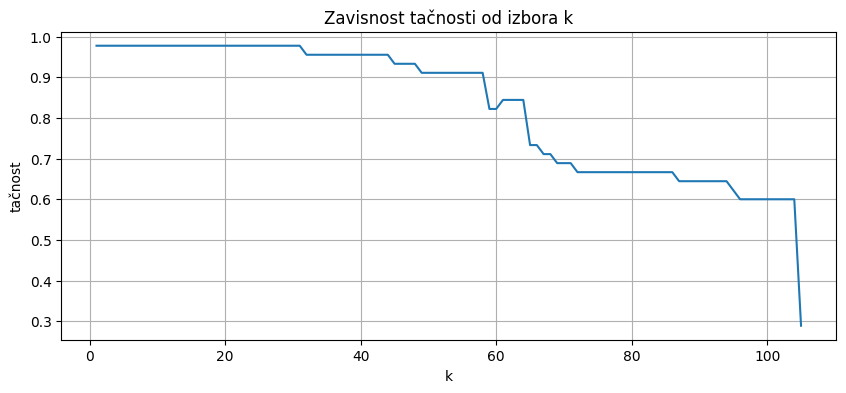

In [ ]:
x_axis = [item['k'] for item in accuracies]
y_axis = [item['accuracy'] for item in accuracies]

plt.figure(figsize=(10, 4))
plt.grid(True)

plt.title('Zavisnost tačnosti od izbora k')
plt.xlabel('k')
plt.ylabel('tačnost')
plt.plot(x_axis, y_axis)

plt.show()

# Zadatak 4

> Koliko slika se nalazi u trening skupu podataka, a koliko u testnom skupu?

U trening skupu podataka se nalazi 60000, a u testnom skupu 10000 slika.

> Koji je oblik ovih varijabli?

*   `X_train.shape` => (60000, 28, 28)
*   `X_test.shape` => (10000, 28, 28)

> Koliko bajta zauzimaju u memoriji?

*   broj bajta trening skupa slika = 44.86083984375 MB
*   broj bajta testnih skupa slika = 7.476806640625 MB

In [ ]:
(X_train, Y_train), (X_test, Y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [ ]:
print(f"Oblici varijabli trening i testnog skupa podataka su {X_train.shape} i {X_test.shape}.")
print(f"Memorijska veličina trening skupa iznosi {X_train.nbytes / 1024**2} MB.")
print(f"Memorijska veličina testnog skupa iznosi {X_test.nbytes / 1024**2} MB.")

Oblici varijabli trening i testnog skupa podataka su (60000, 28, 28) i (10000, 28, 28).
Memorijska veličina trening skupa iznosi 44.86083984375 MB.
Memorijska veličina testnog skupa iznosi 7.476806640625 MB.


> Šta radi naredba `reshape`, a šta `astype`?

Metoda `reshape` mijenja oblik objekta nad kojim je pozvana, konkretno - na osnovu varijabli `X_train` i `X_test` se sada dobijaju oblici (60000, 784) i (10000, 784).

Metoda `astype` konvertuje tip podataka (u ovom slučaju u `float32`).

> Koliko bajta u memoriji sada zauzimaju slike za trening i testiranje?

*   broj bajta trening skupa slika = 179.443359375 MB
*   broj bajta testnih skupa slika = 29.9072265625 MB

In [ ]:
train_images = X_train.reshape((X_train.shape[0], 28 * 28))
train_images = train_images.astype("float32") / 255

test_images = X_test.reshape((X_test.shape[0], 28 * 28))
test_images = test_images.astype("float32") / 255

In [ ]:
print(f"Memorijska veličina trening skupa iznosi {train_images.nbytes / 1024**2} MB.")
print(f"Memorijska veličina testnog skupa iznosi {test_images.nbytes / 1024**2} MB.")

Memorijska veličina trening skupa iznosi 179.443359375 MB.
Memorijska veličina testnog skupa iznosi 29.9072265625 MB.


> Pokušajte istražiti *Keras* dokumentaciju, te se upoznati sa *dense* slojem. Koje sve parametre prima ovaj sloj? Na koji način je on povezan sa narednim slojem, te zašto za ove slojeve kažemo da su potpuno povezani?

*Dense* sloj je potpuno povezani sloj u neuronskoj mreži. To znači da svaki neuron u jednom sloju ima vezu sa svim neuronima iz prethodnog sloja. Neki od ključnih parametara su:

1.   `units` *obavezan* - broj neurona u sloju
2.   `activation` *opcionalan* - aktivacijska funkcija za neuronske izlaze
3.   `input_shape` *potreban samo u prvom sloju* - definiše oblik ulaznih podataka
4.   `use_bias` *opcionalan* - da li sloj koristi *bias* neurone
5.   *i tako dalje...*

In [ ]:
network = models.Sequential()
network.add(layers.Dense(512, activation="relu", input_shape=(28 * 28,)))
network.add(layers.Dense(10, activation="softmax"))

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Kada je model definisan, on se mora pripremiti za treniranje. Kako bi to bilo moguće, model je prvo potrebno kompajlirati.

In [ ]:
network.compile(
    optimizer="rmsprop",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

Prilagođavanje labela izlazu...

> Pomoću *Keras* dokumentacije analizirajte funkciju `to_categorical`.

Funkcija `to_categorical` se koristi za konverziju kategorijskih vrijednosti u `one-hot` vektore. Parametri funkcije su:

1.   `y` *obavezan* - ulazni podaci
2.   `num_classes` *opcionalan* - broj klasa (ako nije zadan, određuje se automatski)
3.   `dtype` *opcionalan* - tip podataka nakon transformacije (podrazumijevano `float32`)

In [ ]:
train_labels = to_categorical(Y_train)
test_labels = to_categorical(Y_test)

Treniranje...

> Pomoću *Keras* dokumentacije pronađite značenje parametara `epochs` i `batch_size`.

*   `epochs`: Definiše broj prolaza kroz cijeli skup podataka tokom treniranja. `epochs=5` znači da će mreža proći kroz sve podatke 5 puta. Veći broj *epochs*-a može poboljšati tačnost, ali i dovesti do *overfitting*-a.
*   `batch_size`: Definiše veličinu grupe podataka koja se šalje kroz mrežu prije ažuriranja težina. `batch_size=128` znači da se 128 slika odjednom obrađuje prije ažuriranja parametara mreže. Manji *batch size* znači sporiji trening, ali bolju generalizaciju. Veći *batch size* znači brži trening, ali može dovesti do slabije sposobnosti mreže da generalizuje.

In [ ]:
network.fit(train_images, train_labels, epochs=5, batch_size=128)

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8720 - loss: 0.4433
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9660 - loss: 0.1161
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9773 - loss: 0.0762
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9841 - loss: 0.0533
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9892 - loss: 0.0366


Evaluacija nad testnim skupom podataka...

> Kolika je tačnost nad testnim skupom podataka? Da li se drastično razlikuje od tačnosti nad trening skupom? Da li je ovo zadovoljavajući rezultat? Zašto jeste/nije?

*   tačnost na trening skupu: 98.91%
*   tačnost na testnom skupu: 97.96%

Razlika je manja od 1%, pa nije drastična. Rezultat je zadovoljavajući s obzirom da tačnost od skoro 98% na testnom skupu pokazuje da model efikasno prepoznaje cifre.

In [ ]:
test_loss, test_acc = network.evaluate(test_images, test_labels)
print("Tacnost za testni skup:", test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9767 - loss: 0.0737
Tacnost za testni skup: 0.9804999828338623
